Qubits:
explain how - phase, modules, and other operation of the complex nums will be used. provide link to the related notebooks in the 'math' with pointing to the specific topic which should be reviewed if forgot the topic

# QML — Week 1: Qubits, State Vectors, Measurement

**Goal of the week:** be able to read and write a quantum state as a vector, predict measurement statistics, and build multi-qubit states — using only `numpy`, then confirm with PennyLane.

| # | Topic | Time |
|---|-------|------|
| 1 | Classical bit vs. qubit (incl. polar form and Euler's formula for amplitudes) | 1 h |
| 2 | State vectors in numpy | 45 min |
| 3 | Measurement and the Born rule | 1 h |
| 4 | Global vs. relative phase | 45 min |
| 5 | Multiple qubits and the tensor product | 1 h |
| 6 | The exponential state space | 30 min |
| 7 | Hands-on with PennyLane | 1 h |
| 8 | Exercises | 1–2 h |
| 9 | Cheat sheet and what's next | 15 min |

**Prerequisites:** linear algebra (vectors, norms, matrix products), basic probability. You already have these from ML.

In [1]:
# pip install numpy matplotlib pennylane
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

---
## 1. Classical bit vs. qubit

### 1.1 What a qubit is

A classical bit is either `0` or `1`. A qubit's state is a **unit vector in a 2-dimensional complex space**:

$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle, \qquad |\alpha|^2 + |\beta|^2 = 1$$

- $\alpha, \beta \in \mathbb{C}$ are **amplitudes** — not probabilities.
- The constraint says the vector has L2 norm 1.

**ML analogy.** Think of a 2-class softmax output, with two differences:
1. Probabilities come from *squared amplitudes*, not from exp-normalization.
2. Amplitudes are signed/complex, so they can **interfere** (cancel or reinforce). Probabilities cannot. Interference is where quantum speedups come from.

| | Classical bit | Qubit |
|---|---|---|
| State | `0` or `1` | $\alpha\lvert0\rangle+\beta\lvert1\rangle$ |
| Description size | 1 bit | 2 complex numbers (1 constraint) |
| Reading it out | exact | probabilistic, destroys the state |

### 1.2 Polar form and Euler's formula — the language of amplitudes

*Complex numbers from scratch (the algebra, the plane, why $i$ exists) are in Week 0, section 1. Here we only need the part that describes a qubit amplitude.*

Instead of $(a,b)$ describe the same point by **length** $r=\lvert z\rvert$ and **angle** $\theta=\arg z$:

$$z = re^{i\theta}=r(\cos\theta+i\sin\theta)$$

Multiplying two complex numbers **multiplies lengths and adds angles** — that is the whole reason complex multiplication is a rotation-and-scaling.

| Symbol | Meaning |
|---|---|
| $\bar z = a - bi$ | complex conjugate: mirror across the real axis |
| $\lvert z\rvert=\sqrt{z\bar z}=\sqrt{a^2+b^2}$ | modulus (always a real number $\ge0$) |
| $\arg z$ | angle from the positive real axis |
| $e^{i\theta}=\cos\theta+i\sin\theta$ | unit-length number; multiplying by it rotates by $\theta$ |

Complex numbers have **no ordering** ("$z_1<z_2$" is meaningless), which is why quantum theory always reports real quantities like $\lvert z\rvert^2$.

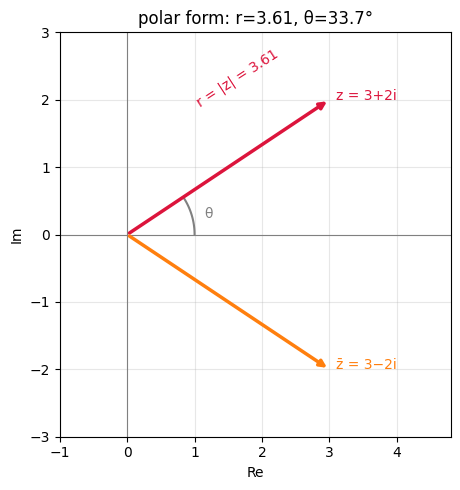

r e^{i theta} = (3+1.9999999999999996j)
angles add, lengths multiply: 2.158798930342464 = 2.158798930342464 | 7.211102550927978 = 7.211102550927978


In [15]:
z = 3 + 2j
r, th = abs(z), np.angle(z)

fig, ax = plt.subplots(figsize=(5.8, 5))
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.annotate("", xy=(z.real, z.imag), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="crimson", lw=2.5))
ax.annotate("", xy=(z.real, -z.imag), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="tab:orange", lw=2.5))
a = np.linspace(0, th, 40); ax.plot(1.0 * np.cos(a), 1.0 * np.sin(a), color="gray")
ax.text(1.15, 0.25, "θ", color="gray"); ax.text(1.0, 1.9, f"r = |z| = {r:.2f}", color="crimson", rotation=33)
ax.text(z.real + 0.1, z.imag, "z = 3+2i", color="crimson"); ax.text(z.real + 0.1, -z.imag, "z̄ = 3−2i", color="tab:orange")
ax.set_xlim(-1, 4.8); ax.set_ylim(-3, 3); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_xlabel("Re"); ax.set_ylabel("Im"); ax.set_title(f"polar form: r={r:.2f}, θ={np.degrees(th):.1f}°")
plt.tight_layout(); plt.show()

print("r e^{i theta} =", r * np.exp(1j * th))
print("angles add, lengths multiply:", np.angle(z * (1j)), "=", th + np.pi / 2, "|", abs(z * 2j), "=", 2 * r)

#### Euler's formula

$$\boxed{e^{i\theta}=\cos\theta+i\sin\theta}$$

**Where it comes from.** The exponential has the series $e^x=\sum_k x^k/k!$. Put $x=i\theta$: the powers of $i$ cycle $1,\,i,\,-1,\,-i,\,1,\dots$, so the even terms assemble into the series of $\cos\theta$ and the odd terms into $i$ times the series of $\sin\theta$.

**Consequences you will use constantly**
- $\lvert e^{i\theta}\rvert=\sqrt{\cos^2\theta+\sin^2\theta}=1$: it lives on the **unit circle**.
- $e^{i\alpha}e^{i\beta}=e^{i(\alpha+\beta)}$: angles add (this *is* the angle-addition formulas for $\cos$ and $\sin$).
- Special points: $e^{i0}=1,\; e^{i\pi/2}=i,\; e^{i\pi}=-1,\; e^{i3\pi/2}=-i$. Euler's identity $e^{i\pi}+1=0$.
- Any complex number: $z=re^{i\theta}$, so the **phase factor** $e^{i\varphi}$ in a quantum amplitude is just a point on this circle.

In [ ]:
import math

theta = 0.8
series = sum((1j * theta) ** k / math.factorial(k) for k in range(15))     # partial sum of e^{x}, x = i*theta
print("series       :", series)
print("exp(i theta) :", np.exp(1j * theta))
print("cos + i sin  :", np.cos(theta) + 1j * np.sin(theta))

print("\ne^{i pi} + 1 =", np.exp(1j * np.pi) + 1, "  (Euler's identity, up to rounding)")
alpha, beta = 0.5, 1.1
print("e^{i a} e^{i b} =", np.exp(1j * alpha) * np.exp(1j * beta), "  e^{i(a+b)} =", np.exp(1j * (alpha + beta)))

fig, ax = plt.subplots(figsize=(5.8, 5.4))
t = np.linspace(0, 2 * np.pi, 300)
ax.plot(np.cos(t), np.sin(t), color="lightgray")
ax.axhline(0, color="gray", lw=0.7); ax.axvline(0, color="gray", lw=0.7)
for k in range(8):
    p = np.exp(1j * k * np.pi / 4)
    ax.scatter([p.real], [p.imag], color="tab:blue", zorder=3)
for lab, (x_, y_), ha in [("1 = e^{i0}", (1.08, 0.09), "left"), ("i = e^{iπ/2}", (0.0, 1.1), "center"),
                          ("−1 = e^{iπ}", (-1.08, 0.09), "right"), ("−i = e^{i3π/2}", (0.0, -1.14), "center")]:
    ax.text(x_, y_, lab, ha=ha, va="center", color="tab:blue")
p = np.exp(1j * theta)
ax.annotate("", xy=(p.real, p.imag), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="crimson", lw=2.5))
ax.plot([p.real, p.real], [0, p.imag], "--", color="tab:green"); ax.plot([0, p.real], [p.imag, p.imag], "--", color="tab:orange")
ax.text(p.real, -0.12, "cos θ", color="tab:green", ha="center"); ax.text(-0.02, p.imag, "sin θ", color="tab:orange", ha="right", va="center")
ax.text(p.real * 0.45, p.imag * 0.65 + 0.12, "e^{iθ}", color="crimson")
ax.set_xlim(-1.9, 1.9); ax.set_ylim(-1.4, 1.4); ax.set_aspect("equal")
ax.set_xlabel("Re"); ax.set_ylabel("Im"); ax.set_title("Euler: e^{iθ} = cos θ + i sin θ  (unit circle)")
plt.tight_layout(); plt.show()

### 1.3 Why this is exactly what a qubit needs

A qubit amplitude must carry **two independent pieces of information**:

1. **How much** — the length $\lvert z\rvert$; its square is a measurement probability.
2. **Which direction** — the angle $\arg z$, the **phase**; invisible in a single measurement but decisive when amplitudes are **added** (interference).

The operations quantum computing needs map onto complex arithmetic:

| Need | Complex arithmetic |
|---|---|
| Rotate an amplitude (a gate) | multiply by $e^{i\theta}$ |
| Combine contributions (superposition, interference) | **add** amplitudes, then take $\lvert\cdot\rvert^2$ |
| Probabilities stay valid | rotations never change $\lvert z\rvert$ |

> **Precision note — convenient, not magic.** Complex numbers are not faster on a computer (a complex product costs 4 real multiplications and 2 additions, the same as the $2\times2$ matrix). A quantum state with $n$ complex amplitudes can be stored as $2n$ reals, so the complex structure is a *convenient and natural language*. It is not strictly dispensable though: a quantum theory using only real amplitudes, with the same rules for composing systems, has been shown to make predictions that experiments contradict (Renou et al., *Nature* 2021). Real numbers alone give you a sign ($\pm$) as "phase"; complex numbers give a **continuous** phase — the smooth knob that quantum algorithms and trainable circuit parameters turn.

**Visualization.** Two paths each contribute amplitude $\tfrac12$, the second with relative phase $\varphi$. Classical probabilities simply add (flat line); amplitudes add *then* get squared, giving $\cos^2(\varphi/2)$ — full cancellation at $\varphi=\pi$.

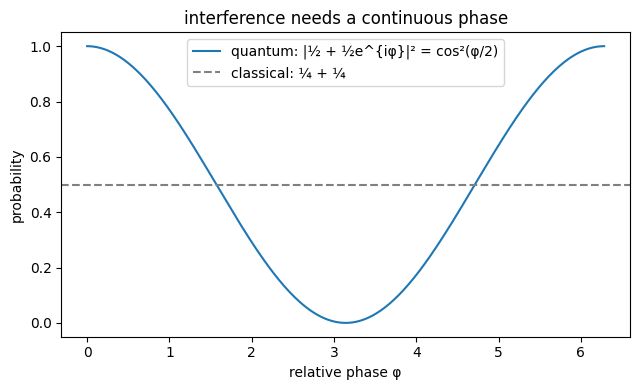

In [16]:
phi = np.linspace(0, 2 * np.pi, 300)
amp = 0.5 + 0.5 * np.exp(1j * phi)                       # two paths, relative phase phi

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(phi, np.abs(amp) ** 2, label="quantum: |½ + ½e^{iφ}|² = cos²(φ/2)")
ax.axhline(0.5, color="gray", ls="--", label="classical: ¼ + ¼")
ax.set_xlabel("relative phase φ"); ax.set_ylabel("probability"); ax.legend()
ax.set_title("interference needs a continuous phase")
plt.tight_layout(); plt.show()

### 1.4 Visualizing a qubit

A classical bit is two points. A qubit is a **point on a sphere** (the Bloch sphere): any pure state is a unit vector $(x, y, z)$ with

$$x = 2\,\mathrm{Re}(\alpha^*\beta), \qquad y = 2\,\mathrm{Im}(\alpha^*\beta), \qquad z = |\alpha|^2 - |\beta|^2$$

- **Poles** $(z=\pm1)$: the classical bits $|0\rangle$ (north) and $|1\rangle$ (south).
- **Equator** $(z=0)$: equal superpositions, differing only in relative phase ($|+\rangle$ on $+x$, $|-\rangle$ on $-x$).
- **Height $z$** sets the measurement probabilities: $P(0) = (1+z)/2$.
- **Angle around the $z$-axis** is the relative phase — invisible to a computational-basis measurement.

Below, each state is shown twice: on the Bloch sphere (the *state*) and as a bar chart (what a *measurement* reveals).

In [ ]:
def bloch_vector(psi):
    a, b = psi
    return np.array([2 * (np.conj(a) * b).real,
                     2 * (np.conj(a) * b).imag,
                     abs(a) ** 2 - abs(b) ** 2])

def draw_bloch(ax, psi, title=""):
    u, v = np.mgrid[0:2*np.pi:40j, 0:np.pi:20j]
    ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v),
                      color="lightgray", alpha=0.35, linewidth=0.5)
    for d in np.eye(3):                                   # x, y, z axes
        ax.plot(*zip(-d, d), color="gray", linewidth=0.8)
    for pos, lab in [((0, 0, 1.25), "|0>"), ((0, 0, -1.3), "|1>"),
                     ((1.3, 0, 0), "|+>"), ((-1.35, 0, 0), "|->")]:
        ax.text(*pos, lab, ha="center", va="center")
    x, y, z = bloch_vector(psi)
    ax.quiver(0, 0, 0, x, y, z, color="crimson", linewidth=2.5, arrow_length_ratio=0.15)
    ax.scatter([x], [y], [z], color="crimson", s=30)
    ax.set_title(title)
    ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()

def show_qubit(states):
    # One column per state: Bloch sphere on top, measurement probabilities below.
    fig = plt.figure(figsize=(3.6 * len(states), 6.4))
    gs = fig.add_gridspec(2, len(states), height_ratios=[2.2, 1])
    for i, (name, psi) in enumerate(states.items()):
        draw_bloch(fig.add_subplot(2, len(states), i + 1, projection="3d"), psi, name)
        ax = fig.add_subplot(gs[1, i])
        ax.bar(["P(0)", "P(1)"], np.abs(psi) ** 2, color=["tab:blue", "tab:orange"])
        ax.set_ylim(0, 1)
        if i: ax.set_yticklabels([])
    fig.tight_layout(); plt.show()

s2 = 1 / np.sqrt(2)
show_qubit({
    "|0>": np.array([1, 0], dtype=complex),
    "|1>": np.array([0, 1], dtype=complex),
    "|+>": np.array([s2, s2], dtype=complex),
    "|->": np.array([s2, -s2], dtype=complex),
})

Notice that $|+\rangle$ and $|-\rangle$ have **identical bar charts** but sit at opposite points on the sphere — the sphere shows the phase that a single measurement hides. We come back to this in section 4.

A state with unequal amplitudes and a non-trivial phase, e.g. $\tfrac{3}{5}|0\rangle + \tfrac{4}{5}e^{i\pi/3}|1\rangle$:

In [ ]:
show_qubit({"3/5|0> + 4/5 e^{i pi/3}|1>": np.array([3/5, 4/5 * np.exp(1j * np.pi / 3)])})

---
## 2. State vectors in numpy

The basis states are the standard basis vectors:

$$|0\rangle = \begin{pmatrix}1\\0\end{pmatrix}, \qquad |1\rangle = \begin{pmatrix}0\\1\end{pmatrix}$$

In [2]:
ket0 = np.array([1, 0], dtype=complex)
ket1 = np.array([0, 1], dtype=complex)

def is_valid_state(psi, tol=1e-9):
    return np.isclose(np.linalg.norm(psi), 1.0, atol=tol)

psi = (3/5) * ket0 + (4/5) * ket1
print("psi =", psi)
print("valid?", is_valid_state(psi))
print("bad state valid?", is_valid_state(np.array([1, 1], dtype=complex)))

psi = [0.6+0.j 0.8+0.j]
valid? True
bad state valid? False


**Bloch sphere (preview).** Any single-qubit state can be written, up to global phase, as

$$|\psi\rangle = \cos\tfrac{\theta}{2}|0\rangle + e^{i\varphi}\sin\tfrac{\theta}{2}|1\rangle$$

so it is fully described by two angles $(\theta, \varphi)$ — a point on a sphere. $|0\rangle$ is the north pole, $|1\rangle$ the south pole. We will rotate these points with gates in Week 2.

In [3]:
def bloch_state(theta, phi):
    return np.array([np.cos(theta/2), np.exp(1j*phi) * np.sin(theta/2)])

for name, (t, p) in {"|0>": (0, 0), "|1>": (np.pi, 0), "|+>": (np.pi/2, 0), "|->": (np.pi/2, np.pi)}.items():
    s = bloch_state(t, p)
    print(f"{name:4s} -> {s}   valid={is_valid_state(s)}")

|0>  -> [1.+0.j 0.+0.j]   valid=True
|1>  -> [0.+0.j 1.+0.j]   valid=True
|+>  -> [0.7071+0.j 0.7071+0.j]   valid=True
|->  -> [ 0.7071+0.j -0.7071+0.j]   valid=True


---
## 3. Measurement and the Born rule

Measuring in the computational basis returns one outcome:

$$P(0) = |\alpha|^2, \qquad P(1) = |\beta|^2$$

and the state **collapses** to the observed basis state. You never see $\alpha,\beta$ directly.

**Consequences for QML**
- A model output is a *statistical estimate*: run the circuit many times (**shots**) and average.
- Estimator noise falls as $1/\sqrt{\text{shots}}$, exactly like Monte Carlo.

In [4]:
def probabilities(psi):
    return np.abs(psi) ** 2

def measure(psi, shots=1000):
    p = probabilities(psi)
    p = p / p.sum()
    outcomes = rng.choice(len(psi), size=shots, p=p)
    return np.bincount(outcomes, minlength=len(psi)) / shots

psi = (3/5) * ket0 + (4/5) * ket1
print("exact   :", probabilities(psi))
print("100 shots:", measure(psi, 100))
print("100k shots:", measure(psi, 100_000))

exact   : [0.36 0.64]
100 shots: [0.34 0.66]
100k shots: [0.3589 0.6411]


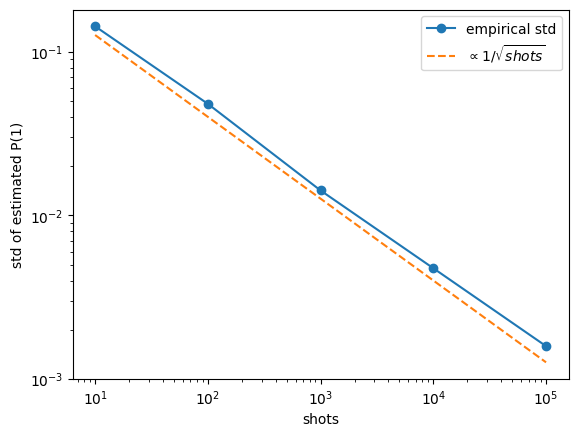

In [5]:
# Estimator noise ~ 1/sqrt(shots)
shots_list = [10, 100, 1_000, 10_000, 100_000]
errors = []
for s in shots_list:
    est = [measure(psi, s)[1] for _ in range(200)]
    errors.append(np.std(est))

plt.loglog(shots_list, errors, "o-", label="empirical std")
plt.loglog(shots_list, 0.4 / np.sqrt(shots_list), "--", label=r"$\propto 1/\sqrt{shots}$")
plt.xlabel("shots"); plt.ylabel("std of estimated P(1)"); plt.legend(); plt.show()

---
## 4. Global vs. relative phase

Compare two states:

$$|+\rangle = \tfrac{1}{\sqrt2}(|0\rangle + |1\rangle), \qquad |-\rangle = \tfrac{1}{\sqrt2}(|0\rangle - |1\rangle)$$

Both give 50/50 under computational-basis measurement, yet they are **different states**. The sign is a *relative phase*, invisible to this measurement but visible after a gate that makes the amplitudes interfere (the Hadamard, in Week 2).

- **Global phase** ($e^{i\gamma}$ multiplying the whole vector): physically unobservable.
- **Relative phase** (between $\alpha$ and $\beta$): observable through interference.

In [6]:
plus  = (ket0 + ket1) / np.sqrt(2)
minus = (ket0 - ket1) / np.sqrt(2)

print("P(|+>)  =", probabilities(plus))
print("P(|->)  =", probabilities(minus))

# Global phase changes nothing observable
g = np.exp(1j * 1.234) * plus
print("P(global-phase |+>) =", probabilities(g))

# But |+> and |-> are orthogonal -> perfectly distinguishable in the right basis
print("<+|-> =", np.vdot(plus, minus))

P(|+>)  = [0.5 0.5]
P(|->)  = [0.5 0.5]
P(global-phase |+>) = [0.5 0.5]
<+|-> = (-2.2371143170757382e-17+0j)


---
## 5. Multiple qubits and the tensor product

Two qubits live in the **tensor (Kronecker) product** of two 2-d spaces — a 4-d space:

$$|0\rangle\otimes|1\rangle = |01\rangle = (0,1,0,0)^T$$

General 2-qubit state: $\;a|00\rangle + b|01\rangle + c|10\rangle + d|11\rangle$ with $\sum|\cdot|^2 = 1$.

**Product states vs. entangled states**
- *Product state*: can be written as $|\psi_A\rangle\otimes|\psi_B\rangle$.
- *Entangled state*: cannot. Example, the Bell state $\tfrac{1}{\sqrt2}(|00\rangle+|11\rangle)$.

ML analogy: a product state is like a *rank-1* joint distribution (independent features); an entangled state carries correlations that no product of marginals can reproduce.

In [7]:
ket00 = np.kron(ket0, ket0)
ket01 = np.kron(ket0, ket1)
print("|01> =", ket01.real)

# Product state: |+> ⊗ |0>
prod = np.kron(plus, ket0)
print("|+>⊗|0> =", prod)

# Bell state
bell = (np.kron(ket0, ket0) + np.kron(ket1, ket1)) / np.sqrt(2)
print("Bell =", bell)
print("P(bell) over 00,01,10,11 =", probabilities(bell))

|01> = [0. 1. 0. 0.]
|+>⊗|0> = [0.7071+0.j 0.    +0.j 0.7071+0.j 0.    +0.j]
Bell = [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]
P(bell) over 00,01,10,11 = [0.5 0.  0.  0.5]


In [8]:
# Is a 2-qubit state a product state? Reshape to 2x2 and look at the singular values (Schmidt decomposition).
def schmidt_coeffs(psi):
    return np.linalg.svd(psi.reshape(2, 2), compute_uv=False)

print("product :", schmidt_coeffs(prod))   # one non-zero value  -> product
print("bell    :", schmidt_coeffs(bell))   # two equal values    -> maximally entangled

product : [1. 0.]
bell    : [0.7071 0.7071]


> **Why that works.** Reshaping the 4-vector into a 2×2 matrix $M$, a product state is exactly a *rank-1* matrix. The number of non-zero singular values (the Schmidt rank) measures entanglement — familiar SVD, new meaning.

---
## 6. The exponential state space

$n$ qubits $\Rightarrow$ $2^n$ amplitudes.

| qubits | amplitudes | memory (complex128) |
|---|---|---|
| 10 | 1,024 | 16 KB |
| 30 | ~10⁹ | 16 GB |
| 40 | ~10¹² | 16 TB |
| 50 | ~10¹⁵ | 16 PB |

This is why classical simulation breaks down around 40–50 qubits — and why people hope for quantum advantage. It is **not** a free lunch: measurement returns only $n$ classical bits per shot.

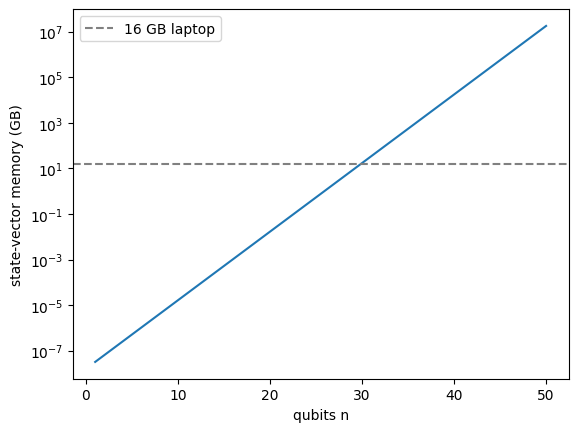

In [9]:
ns = np.arange(1, 51)
mem_bytes = (2.0 ** ns) * 16
plt.semilogy(ns, mem_bytes / 1e9)
plt.axhline(16, color="gray", ls="--", label="16 GB laptop")
plt.xlabel("qubits n"); plt.ylabel("state-vector memory (GB)"); plt.legend(); plt.show()

---
## 7. Hands-on with PennyLane

Confirm the numpy results with a real framework. We only use the Hadamard gate as a black box here — Week 2 explains gates properly.

In [10]:
import pennylane as qml

dev = qml.device("default.qubit", wires=1)

@qml.qnode(dev)
def plus_state():
    qml.Hadamard(wires=0)
    return qml.state()

print("state :", plus_state())

ModuleNotFoundError: No module named 'pennylane'

In [ ]:
# Finite shots -> sampling noise, just like our measure()
dev_shots = qml.device("default.qubit", wires=1, shots=1000)

@qml.qnode(dev_shots)
def plus_probs():
    qml.Hadamard(wires=0)
    return qml.probs(wires=0)

for _ in range(3):
    print(plus_probs())

In [ ]:
# Bell state on 2 qubits
dev2 = qml.device("default.qubit", wires=2)

@qml.qnode(dev2)
def bell_circuit():
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0, 1])
    return qml.state()

print("PennyLane Bell:", bell_circuit())
print("our numpy Bell:", bell)

---
## 8. Exercises

Fill in the code cells. Try on paper first, then verify.

**Exercise 1 — validity.** Is $\tfrac{3}{5}|0\rangle + \tfrac{4}{5}|1\rangle$ a valid state? What are $P(0)$, $P(1)$?

In [ ]:
# TODO

**Exercise 2 — normalize.** Write `normalize(v)` and use it to turn $(1, 2i)$ into a valid state. Report $P(0)$, $P(1)$.

In [ ]:
def normalize(v):
    # TODO
    pass

**Exercise 3 — phase.** Show numerically that $|+\rangle$ and $|-\rangle$ have identical computational-basis statistics, but $\langle +|-\rangle = 0$. Why does that not contradict "identical statistics"?

In [ ]:
# TODO

**Exercise 4 — amplitudes of 3 qubits.** How many amplitudes describe a 3-qubit state? Build $|+\rangle^{\otimes 3}$ with `np.kron` and verify all 8 probabilities equal $1/8$.

In [ ]:
# TODO

**Exercise 5 — entanglement detector.** Use `schmidt_coeffs` on three random 2-qubit states: (a) a random product state, (b) the Bell state, (c) a random normalized 4-vector. Which are entangled?

In [ ]:
# TODO

**Exercise 6 (stretch) — shots.** How many shots do you need to estimate $P(1)$ of $\tfrac{3}{5}|0\rangle+\tfrac{4}{5}|1\rangle$ to within ±0.01 (one std)? Check by simulation.

In [ ]:
# TODO

---
## 9. Cheat sheet and what's next

| Concept | One-liner |
|---|---|
| Qubit state | unit vector $(\alpha,\beta)\in\mathbb{C}^2$ |
| Born rule | $P(i)=\lvert\text{amplitude}_i\rvert^2$ |
| Measurement | random, collapses state, $1/\sqrt{\text{shots}}$ noise |
| Global phase | unobservable |
| Relative phase | observable via interference |
| $n$ qubits | $2^n$-dim vector, built with `np.kron` |
| Entanglement | state is not a Kronecker product (Schmidt rank > 1) |

**Next — Week 2: Gates, simulation, hardware, advantage.** Gates are unitary matrices ($U^\dagger U = I$) — norm-preserving rotations. We cover X, Z, H, RX/RY/RZ and CNOT, see why $|+\rangle$ and $|-\rangle$ differ, build a state-vector simulator, look at how real quantum hardware executes circuits, and ask honestly where quantum beats classical.
